# Tutorial 03: one call, from population model to $\Omega_{\rm GW}(f)$ (no spins)

The first two chapters reproduced the whole BUILD stage. This chapter reproduces the **CALL** stage. This is the code that runs at every MCMC step; it is only about 30 lines.

| Section | Source | Step |
|---|---|---|
| 1 | `_mass_grid`, `mfun(...) * jac` | mass model → density in $(\ln M,\ln q)$ |
| 2 | `reshape(...).mean`, `/ sum`, `* _cell` | cell average, normalisation, probability per cell $P_{\ell s}$ |
| 3 | `P @ Cbar[:, :, 0].T` | projection onto the SVD modes: $\hat P_{\ell r}$ |
| 4 | `_zw * _rate(...)` | redshift weights $\rho_j$ |
| 5 | `irfft(rfft(P) * rfft(w))` | redshift convolution $K_{dr}$ |
| 6 | `K * _e4l` | mass power |
| 7 | `rfft(B[::-1]) * _FJ` ... | frequency cross-correlation $S_k$ |
| 8 | `interp_uniform` | interpolation to the user frequencies |
| 9 | `* exp(-A ln(T f)) * 4π²f³/(3H0²)` | undo the preconditioning, add the prefactor |

At the end, compare with `fo.omega(...)` and with the jitted `fo.make(...)`.

In [1]:
import os
for k in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ[k] = "1"

In [2]:
%matplotlib inline
import sys
sys.path.append("../")
FIGDIR = "../../Figures/"

In [3]:
import numpy as np
import matplotlib.pyplot as plt

import seaborn as sns
sns.set(style='ticks', context='notebook', font='serif', 
        font_scale=1.5, palette='deep')
plt.rcParams.update({
    "text.usetex": True,
    "text.latex.preamble": r"\usepackage{amssymb}\usepackage{mathrsfs}\usepackage{bm}", 
    "font.family": "serif",
    'backend': 'pdf',
    # Grid
    "axes.grid": True,
    "grid.alpha": 0.7,
    "grid.linewidth": 0.4,

    # Ticks
    "xtick.direction": "in",
    "ytick.direction": "in",
    'xtick.labelsize': 18,
    'ytick.labelsize': 18,
    # Font
    'font.size': 18,
    'legend.fontsize': 18,
})


import jax
jax.config.update("jax_enable_x64", True)
import jax.numpy as jnp

from stochaxtic import jax_populations as jp
from stochaxtic.fast_omega import FastOmega, T_SUN, A_PRE, DEFAULT_N_SUB
from stochaxtic.constants import H0_SI

def check(name, mine, ref):
    mine, ref = np.asarray(mine), np.asarray(ref)
    assert mine.shape == ref.shape, (name, mine.shape, ref.shape)
    rel = np.max(np.abs(mine - ref)) / np.max(np.abs(ref))
    print(f"{name:26s} shape {str(ref.shape):14s} max |diff| / max |ref| = {rel:.1e}")
    return rel

fo = FastOmega()
mass, rate = "bpl_double_gaussian", "madau_dickinson"
d = fo.info["delta"]
n_l, n_z, n_d, n_f = fo._n_l, fo._n_z, fo._n_d, fo._n_f
print("mass defaults:", jp.MASS_MODELS[mass][1])
print("rate defaults:", jp.RATE_DEFAULTS[rate])

FastOmega: SVD loaded from /home/haowen.zhong/.cache/stochaxtic/svd_IMRPhenomXAS_f596ad348a1a949f.npz
FastOmega: IMRPhenomXAS, spins=None, tides=False: 121 table columns, rank 8; grids lnM 1231, z 444, lnq 121, lnf 1061; setup 0.1 s
mass defaults: {'alpha_m_1': 1.5754278453802124, 'alpha_m_2': 5.663286019662541, 'beta_q': 0.5572915358861987, 'm_break': 38.06724241851806, 'mu_m_1': 10.135808238284675, 'sigma_m_1': 0.6612470197196616, 'mu_m_2': 35.07723569532331, 'sigma_m_2': 3.1243701779940696, 'm_1_min': 4.121538752270456, 'm_max': 300.0, 'lambda_peak_1': 0.49341832652035744, 'lambda_peak_2': 0.47992177777376155, 'delta_m_1': 4.352759439353479, 'm_2_min': 3.42818414788367, 'delta_m_2': 5.8893002445024685}
rate defaults: {'R0': 17.99719280349701, 'alpha': 2.850042173338945, 'zp': 2.270700222839242, 'beta': 6.990668900157332}


## 1. Mass model → density in $(\ln M,\ln q)$

The mass model gives $p(m_1,m_2)$. FastOmega's grid is in $(\ln M,\ln q)$, so multiply by the Jacobian:
$$m_1=\frac{M}{1+q},\ m_2=\frac{Mq}{1+q}\ \Rightarrow\ dm_1\,dm_2=\frac{M}{(1+q)^2}\,dM\,dq=\frac{M^2q}{(1+q)^2}\,d\ln M\,d\ln q .$$

**Sub-sampling**: each $\ln M$ cell is sampled at `n_sub` points (spread uniformly inside the cell) that are then averaged. For smooth models (BPL+2G has Planck windows) one point is enough; models with hard edges default to 4, and the cell average smooths the hard edge.

The parameter dict also gets an extra entry `"_w"`: hard cuts are replaced by logistic soft edges of width `_w` (one sub-sampling step, in $\ln m$). This is for **differentiability** (see chapter 06).

In [4]:
n_sub = DEFAULT_N_SUB.get(mass, 4)                       # 1 for bpl_double_gaussian
sub = (np.arange(n_sub) + 0.5) / n_sub - 0.5              # offsets inside a ln M cell, in units of d
M = np.exp(fo.l_src[:, None] + d * sub[None, :]).reshape(-1)[:, None]
q = np.exp(fo.lq)[None, :]
m1, m2, jac = M / (1 + q), M * q / (1 + q), M ** 2 * q / (1 + q) ** 2
for name, mine, ref in zip(("m1", "m2", "jacobian"), (m1, m2, jac), fo._mass_grid(n_sub)):
    check(name, mine, ref)

mfun, mdef = jp.MASS_MODELS[mass]
mp = {**mdef, "_w": d / n_sub}
p_dens = mfun(m1, m2, mp) * jac                            # density in (ln M, ln q)
print("p_dens:", p_dens.shape)

m1                         shape (1231, 121)    max |diff| / max |ref| = 0.0e+00
m2                         shape (1231, 121)    max |diff| / max |ref| = 0.0e+00
jacobian                   shape (1231, 121)    max |diff| / max |ref| = 0.0e+00
p_dens: (1231, 121)


## 2. Cell average, normalisation, probability per cell

Three lines:
1. average the `n_sub` sub-samples into the cell average $\bar p_{\ell s}$;
2. normalise so that $\sum_{\ell s}\bar p_{\ell s}\,\delta\,w_s=1$ ($\delta$ is the $\ln M$ cell width and $w_s$ the Simpson weight in $\ln q$; their product is `_cell`);
3. multiply by `_cell` once more, turning the **density** into a **probability per cell** $P_{\ell s}$, so that $\sum_{\ell s}P_{\ell s}=1$.

Note that the normalisation is done **on the grid**: the model's own normalisation constant does not matter, and any part outside the grid is dropped. That is why `check_support` exists: it confirms that the grid covers the population (`make()` checks the default parameters automatically).

sum of P = 0.9999999999999993    shape (1231, 121)


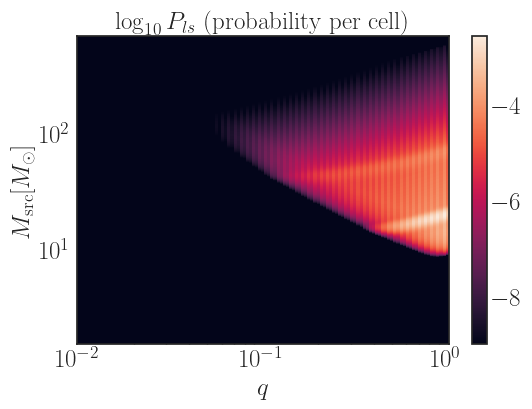

In [6]:
P = p_dens.reshape(n_l, n_sub, -1).mean(axis=1)
P = P / jnp.sum(P * fo._cell)
P = P * fo._cell
print("sum of P =", float(P.sum()), "   shape", P.shape)

fig, ax = plt.subplots(figsize=(6, 4))
im = ax.pcolormesh(np.exp(fo.lq), np.exp(fo.l_src), np.log10(np.maximum(np.asarray(P), 1e-12)),
                   shading="auto", vmin=-9)
ax.set(xscale="log", yscale="log", xlabel=r"$q$", ylabel=r"$M_{\rm src} [M_\odot]$", title=r"$\log_{10} P_{ls}$ (probability per cell)")
plt.colorbar(im);

## 3. Projection onto the SVD modes

Without spins the coefficients are just $C_{rs}$ (`fo._C[:, :, 0, 0]`): `_spin_coefficients` returns `_C[..., 0]` when `spins=None`. The spin case is the subject of chapter 04.

$$\hat P_{\ell r}=\sum_s P_{\ell s}\,C_{rs}.$$

Meaning: $J_{ms}\approx\sum_rB_{mr}C_{rs}$, so $\sum_sP_{\ell s}J_{ms}=\sum_rB_{mr}\hat P_{\ell r}$. **The $q$ integral is already done**, with only $n_\ell\times n_q\times R$ multiplications, and the index $q$ is never needed again.

In [7]:
Cbar = fo._spin_coefficients("gwtc5_default", dict(jp.SPIN_MODELS["gwtc5_default"][1]))   # no spins: = fo._C[..., 0]
check("Cbar (no spins) = C", Cbar, np.asarray(fo._C)[..., 0])
P_hat = P @ Cbar[:, :, 0].T
print("P_hat:", P_hat.shape)

Cbar (no spins) = C        shape (8, 121, 1)    max |diff| / max |ref| = 0.0e+00
P_hat: (1231, 8)


In [8]:
P.shape, (Cbar).shape, (Cbar[:, :, 0].T).shape

((1231, 121), (8, 121, 1), (121, 8))

## 4. Redshift weights $\rho_j$

$\rho_j=\zeta_j\,\mathcal R(z_j)$, where $\zeta_j$ is `_zw` from chapter 02 (redshift measure × $1/d_L^2$) and $\mathcal R$ is the population's merger rate density (Gpc$^{-3}$yr$^{-1}$). The redshift hyperparameters enter **only in this line**. Every rate model in `jp.RATE_MODELS` is a function $\mathcal R(z)$ of any $z$ (an array of any shape), including the time-delayed `madau_dickinson_timedelay`, whose delay integral uses tables that depend only on the cosmology; `fo._rate` uses one built for this FastOmega's cosmology.

(0.2, 10.0)

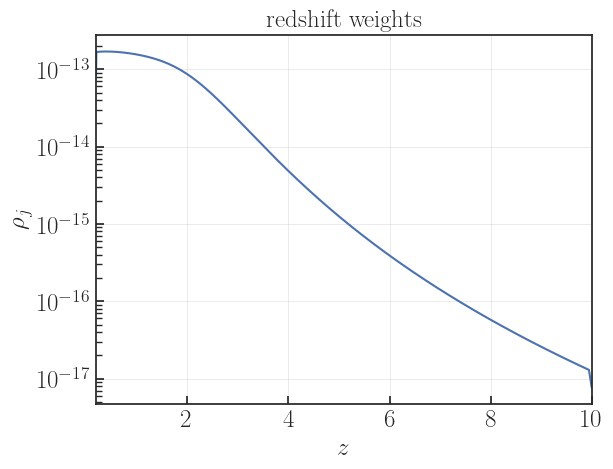

In [9]:
rp = dict(jp.RATE_DEFAULTS[rate])
w = fo._zw * jp.RATE_MODELS[rate](jnp.asarray(fo.z), rp)
plt.semilogy(fo.z, np.asarray(w))
plt.xlabel(r"$z$") 
plt.ylabel(r"$\rho_j$") 
plt.title("redshift weights");
plt.xlim(0.2, 10)

## 5. Redshift convolution: source frame → detector frame

$$K_{dr}=\sum_j\rho_j\,\hat P_{d-j,\,r}.$$

Since $\ell^{\rm det}_d=\ell_{d-j}+\xi_j$, this reads: "move the contribution of source-frame mass $\ell$ to detector-frame mass $\ell+\xi_j$, with the redshift weight $\rho_j$". It is a **convolution**, done with one FFT per mode $r$ (length `L1`, zero-padded against wrap-around), keeping the first $n_d$ points.

Compute it with the FFT, then check one mode against `np.convolve` (the direct sum):

In [10]:
P_hat.shape

(1231, 8)

In [11]:
L1 = fo._L1
K = jnp.fft.irfft(jnp.fft.rfft(P_hat, n=L1, axis=0) * jnp.fft.rfft(w, n=L1)[:, None], n=L1, axis=0)[:n_d]
r = 0
K_direct = np.convolve(np.asarray(P_hat[:, r]), np.asarray(w))[:n_d]      # full linear convolution
check("K[:, 0] FFT vs direct sum", K[:, r], K_direct)
print("K:", K.shape)

K[:, 0] FFT vs direct sum  shape (1674,)        max |diff| / max |ref| = 4.2e-16
K: (1674, 8)


## 6. Mass power

$I=M_{\rm det}^4J$, and $M^A$ was already moved into the table in chapter 02 ($\tilde B=Bx^A$); here we multiply by the remaining $M_{\rm det}^{4-A}$ (`_e4l`).

In [12]:
Bk = K * fo._e4l              # (n_d, R); the source code reuses the name B for this array

## 7. Frequency cross-correlation: all frequencies with one FFT

We need
$$S_k=\sum_r\sum_d\,\underbrace{K_{dr}e_d}_{\texttt{Bk}}\;\tilde B_{d+k,\,r}\qquad(k=0,\dots,n_f-1).$$
The index is $d+k$, so this is a **cross-correlation**, not a convolution. The trick: **reverse** `Bk` along $d$, $\texttt{Bk}^{\rm rev}_{n_d-1-d}=\texttt{Bk}_d$, which turns the correlation into a convolution:
$$S_k=\sum_d\texttt{Bk}^{\rm rev}_{n_d-1-d}\,\tilde B_{d+k}=(\texttt{Bk}^{\rm rev}*\tilde B)_{\,n_d-1+k}.$$
So read the convolution at the points $n_d-1$ to $n_d-1+n_f-1$. The FFT of $\tilde B$ (`_FJ`) was computed in the constructor; each call only needs a (batched) FFT of `Bk`, a product, a sum over $r$ and an inverse FFT.

The sum over $r$ is done in the frequency domain (`jnp.sum(FB * _FJ, axis=1)`), so there is **one** inverse FFT instead of $R$.

In [13]:
L2 = fo._L2
FB = jnp.fft.rfft(Bk[::-1], n=L2, axis=0)
c = jnp.fft.irfft(jnp.sum(FB * fo._FJ, axis=1), n=L2)
S = c[n_d - 1:n_d - 1 + n_f]

# check a few k against the direct double sum
Bt = np.asarray(fo._B) * np.exp(A_PRE * fo.ln_x)[:, None]          # tilde B on the fine x grid
for k in (0, 300, 700, n_f - 1):
    direct = np.sum(np.asarray(Bk) * Bt[k:k + n_d])
    print(f"k={k:5d}  FFT {float(S[k]): .6e}   direct {direct: .6e}   rel diff {abs(float(S[k]) / direct - 1):.1e}")

k=    0  FFT  1.190136e-59   direct  1.190136e-59   rel diff 0.0e+00
k=  300  FFT  9.795003e-60   direct  9.795003e-60   rel diff 0.0e+00
k=  700  FFT  6.575500e-60   direct  6.575500e-60   rel diff 4.4e-16
k= 1060  FFT  4.072429e-62   direct  4.072429e-62   rel diff 2.6e-15


## 8–9. Interpolate to the user frequencies, undo the preconditioning, add the prefactor

$S_k$ lives on the uniform $\ln f$ grid. Since the preconditioning flattened the inspiral, it is a gentle curve, and linear interpolation (`interp_uniform`, an O(1) lookup, faster than the binary search of `jnp.interp`) is accurate. Finally

$$\Omega_{\rm GW}(f)=S(f)\,(T_\odot f)^{-A}\,\frac{4\pi^2f^3}{3H_0^2}.$$

$(T_\odot f)^{-A}$ gives back the frequency share of the factor $x^A=(T_\odot M_{\rm det}f)^A$ put into the table in chapter 02 (the mass share was already taken out by $M^{4-A}$ in step 6).

Omega: mine vs fo.omega    shape (996,)         max |diff| / max |ref| = 0.0e+00
Omega: mine vs jitted make() shape (996,)         max |diff| / max |ref| = 3.2e-15


(5, 1000)

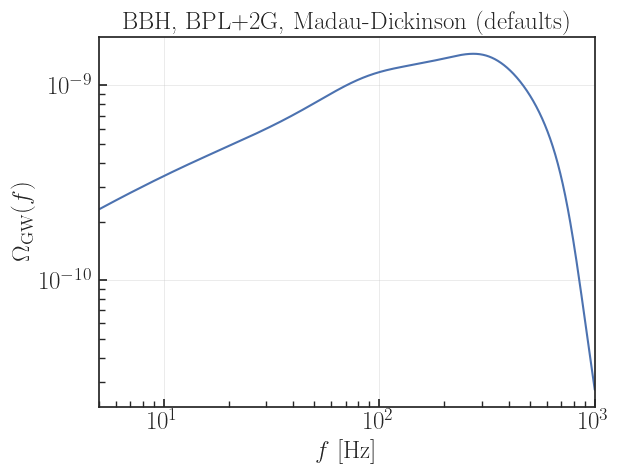

In [17]:
lnf = jnp.asarray(np.log(fo.freqs))
S_out = jp.interp_uniform(lnf, fo.lnf[0], d, S)
Omega_mine = S_out * jnp.exp(-A_PRE * (np.log(T_SUN) + lnf)) * 4 * np.pi ** 2 * jnp.exp(3 * lnf) / (3 * H0_SI ** 2)


Omega_ref = fo.omega(mass, rate)
check("Omega: mine vs fo.omega", Omega_mine, Omega_ref)
omega_jit = fo.make(mass, rate)
check("Omega: mine vs jitted make()", Omega_mine, omega_jit())

plt.loglog(fo.freqs, np.asarray(Omega_mine))
plt.xlabel(r"$f$ [Hz]")
plt.ylabel(r"$\Omega_{\rm GW}(f)$")
plt.title("BBH, BPL+2G, Madau-Dickinson (defaults)")
plt.xlim(5, 1000)


## 10. Exercise: change one hyperparameter

`omega(mass_params, rate_params)` only needs the parameters you want to change; the others keep their defaults. For example, double the local rate $R_0$ ($\Omega$ must double exactly), or move the peak $z_p$ of $\mathcal R(z)$:

R0 x 2  ->  Omega ratio: 2.0000000000000013


(5, 1000)

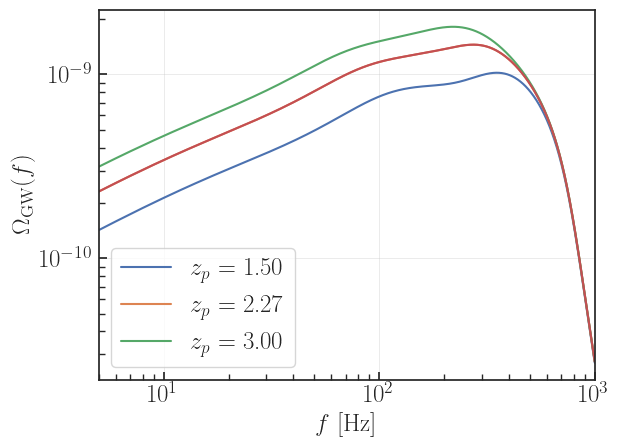

In [18]:
om = fo.make(mass, rate)
base = om()
print("R0 x 2  ->  Omega ratio:", float(om(None, {"R0": 2 * rp["R0"]})[50] / base[50]))

for zp in (1.5, 2.27, 3.0):
    plt.loglog(fo.freqs, np.asarray(om(None, {"zp": zp})), label=fr"$z_p$ = {zp:.2f}")
plt.loglog(fo.freqs, np.asarray(Omega_mine))
plt.xlabel(r"$f$ [Hz]")
plt.ylabel(r"$\Omega_{\rm GW}(f)$")
plt.legend()
plt.xlim(5, 1000)

## Summary: the whole cost of one call

| Step | Operation | Size (default) |
|---|---|---|
| 1–2 | point-wise mass model | $1231\times121$ |
| 3 | matrix product | $1231\times121\times8$ |
| 4 | point-wise merger rate | 444 |
| 5 | 8 FFTs (length 2048) + 1 | |
| 7 | 8 FFTs (length 8192) + 1 inverse FFT | |
| 8–9 | interpolation + point-wise operations | 996 output frequencies |

No waveforms and no random numbers. **The hyperparameters enter only in step 1 (mass) and step 4 (redshift)**; everything after them is linear. That is why the call is both fast (a few ms after jit, chapter 06) and differentiable.

**Next chapter (04)**: switch on spins. The table gets $n_{\rm spin}$ times more columns, and step 3 is preceded by an importance-weighted average; nothing else changes.